# 01. EMG Signal Exploration and Dataset Inspection
**Project:** Analysis of Physical Actions Using EMG Signal Classification  
**Target Environment:** Google Colab / Jupyter Notebook  

---

### Notebook Overview
Surface electromyography (sEMG) captures the electrical activity generated by skeletal muscle contractions during motor execution. In this project, we analyze the **EMG Physical Action Data Set**, which consists of 8-channel sEMG signals recorded across 4 subjects performing 20 distinct physical actions divided into two broad behavioral categories:
1. **Normal Actions (10 classes):** Everyday non-combative actions (e.g., Bowing, Clapping, Walking).
2. **Aggressive Actions (10 classes):** High-intensity combative movements (e.g., Punching, Kicking, Elbowing).

### Objectives of this Notebook
1. **Google Drive Integration:** Mount Google Drive in Google Colab to access the uploaded/shared dataset.
2. **Directory Structure Verification:** Locate and inspect the folder hierarchy of the dataset (`sub1` through `sub4`, and their `txt/` and `log/` subfolders).
3. **Action Inventory & Validation:** Verify the presence of all 20 action recordings across subjects and handle file naming variations (such as `Hamering` vs. `Hammering`).
4. **8-Channel Signal Verification:** Confirm that every recording contains exactly 8 numerical EMG channels corresponding to the physical muscle sensor placements.
5. **Signal Dimension Reporting:** Display the size and shape `(N_samples, 8)` of individual signal arrays and aggregate summary statistics across all subjects.
6. **Multi-Channel Visualization:** Plot time-series waveforms across all 8 channels for representative Normal and Aggressive actions to observe muscle recruitment patterns.

In [5]:
# Step 1: Environment Setup and Library Imports
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configure matplotlib styling for clear, readable figures
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['figure.titlesize'] = 15

print("Libraries imported successfully.")

Libraries imported successfully.


---
## 1. Google Drive Mounting & Dataset Setup

If your dataset is stored in Google Drive (e.g., from the shared link `https://drive.google.com/drive/folders/1qRhw4-W7QCJVh7oLJjysbSUlKHDFT-sB`):

1. **Add Shortcut to My Drive (if using a shared link):**
   - Open the shared link in your browser.
   - Click the folder name dropdown or right-click the folder → select **Organize** → **Add shortcut** → select **My Drive**.
2. **Mount Google Drive:**
   - Running the code cell below executes `drive.mount('/content/drive')`. Colab will prompt you to authorize access.
3. **Path Resolution:**
   - Once mounted, your folder will be accessible at `/content/drive/MyDrive/...`.
   - The cell below automatically scans common candidate paths in Google Drive and falls back gracefully to a configurable path.

In [6]:
# Step 2: Mount Google Drive and Configure Dataset Path

# Mount Google Drive if running inside Google Colab
try:
    from google.colab import drive
    drive.mount('/content/drive')
    print("Google Drive successfully mounted at /content/drive")
except ImportError:
    print("Not running in Google Colab; using local file system.")

# Candidate locations in Google Drive and Colab runtime
CANDIDATE_PATHS = [
    Path("/content/drive/MyDrive/EMGPhysicalActionDataSet"),
    Path("/content/drive/MyDrive/EMG Physical Action Data Set"),
    Path("/content/drive/MyDrive/EMGPhysicalAction"),
    Path("/content/EMGPhysicalActionDataSet"),
    Path("./EMGPhysicalActionDataSet")
]

# Configurable dataset root path (adjust if your folder in My Drive has a custom name)
DATASET_ROOT = None
for candidate in CANDIDATE_PATHS:
    if candidate.exists() and any(candidate.glob("sub*")):
        DATASET_ROOT = candidate
        break

if DATASET_ROOT is None:
    # Default to Google Drive My Drive path
    DATASET_ROOT = Path("/content/drive/MyDrive/EMGPhysicalActionDataSet")
    print(f"Default dataset path configured to: {DATASET_ROOT}")
    print("Tip: If your folder has a different name in My Drive, update DATASET_ROOT above.")
else:
    print(f"Verified dataset root directory located at: {DATASET_ROOT}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive successfully mounted at /content/drive
Verified dataset root directory located at: /content/drive/MyDrive/EMGPhysicalActionDataSet


---
## 2. Channel Metadata and Action Classes

The 8 recording electrodes are mapped to specific anatomical muscle sites on the upper and lower extremities:
* **CH1:** Right Biceps (Upper Arm)
* **CH2:** Right Triceps (Upper Arm)
* **CH3:** Left Biceps (Upper Arm)
* **CH4:** Left Triceps (Upper Arm)
* **CH5:** Right Thigh (Upper Leg)
* **CH6:** Right Hamstring (Upper Leg)
* **CH7:** Left Thigh (Upper Leg)
* **CH8:** Left Hamstring (Upper Leg)

In [7]:
# Step 3: Sensor Channel Descriptions and Action Definitions

# Sensor Channel Descriptions (8 Channels)
CHANNEL_NAMES = [
    "CH1: Right Biceps",
    "CH2: Right Triceps",
    "CH3: Left Biceps",
    "CH4: Left Triceps",
    "CH5: Right Thigh",
    "CH6: Right Hamstring",
    "CH7: Left Thigh",
    "CH8: Left Hamstring"
]

# 10 Normal action classes
NORMAL_ACTIONS = [
    "Bowing", "Clapping", "Handshaking", "Hugging", "Jumping",
    "Running", "Seating", "Standing", "Walking", "Waving"
]

# 10 Aggressive action classes (handling both 'Hamering' and 'Hammering' variants)
AGGRESSIVE_ACTIONS = [
    "Elbowing", "Frontkicking", "Hamering", "Headering", "Kneeing",
    "Pulling", "Punching", "Pushing", "Sidekicking", "Slapping"
]

ALL_ACTIONS = NORMAL_ACTIONS + AGGRESSIVE_ACTIONS
EXPECTED_SUBJECTS = ["sub1", "sub2", "sub3", "sub4"]

print(f"Total action classes defined: {len(ALL_ACTIONS)} (10 Normal, 10 Aggressive)")
print(f"EMG Channels monitored: {len(CHANNEL_NAMES)}")

Total action classes defined: 20 (10 Normal, 10 Aggressive)
EMG Channels monitored: 8


---
## 3. Dataset Hierarchy and Subject Discovery

We now inspect the directory structure. The standard structure is:
```text
EMGPhysicalActionDataSet/
├── sub1/
│   ├── txt/
│   └── log/
├── sub2/
...
```
We write flexible inspection logic that searches for subject folders (`sub1` to `sub4`), reports available subfolders (`txt/`, `log/`), and counts files without making brittle assumptions.

In [8]:
# Step 4: Inspect Dataset Hierarchy and Subject Subdirectories

def inspect_dataset_directory(dataset_root: Path):
    """
    Inspects the dataset root directory, verifies subject folders,
    and reports subdirectories and file counts.
    """
    if not dataset_root.exists():
        raise FileNotFoundError(
            f"Dataset root directory not found at: {dataset_root}\n"
            f"Please verify that Google Drive is mounted and the folder path is correct."
        )

    # Discover subject directories (case-insensitive match for 'sub1', 'sub2', etc.)
    subject_dirs = [d for d in dataset_root.iterdir() if d.is_dir() and d.name.lower().startswith("sub")]
    subject_dirs = sorted(subject_dirs, key=lambda d: d.name.lower())

    if not subject_dirs:
        # Fallback: check if subfolders are directly in dataset_root
        all_dirs = [d for d in dataset_root.iterdir() if d.is_dir()]
        raise FileNotFoundError(
            f"No subject folders (e.g., 'sub1', 'sub2') found in {dataset_root}.\n"
            f"Available directories found: {[d.name for d in all_dirs]}"
        )

    print(f"Found {len(subject_dirs)} subject directories in {dataset_root.name}:")

    summary_rows = []
    for s_dir in subject_dirs:
        subfolders = [d.name for d in s_dir.iterdir() if d.is_dir()]
        txt_count = len(list(s_dir.rglob("*.txt")))
        log_count = len(list(s_dir.rglob("*.log")))
        total_data_files = txt_count + log_count
        summary_rows.append({
            "Subject": s_dir.name,
            "Subdirectories": ", ".join(subfolders) if subfolders else "None (direct files)",
            ".txt files": txt_count,
            ".log files": log_count,
            "Total Data Files": total_data_files
        })

    summary_df = pd.DataFrame(summary_rows)
    print(summary_df.to_string(index=False))
    return subject_dirs

subject_dirs = inspect_dataset_directory(DATASET_ROOT)

Found 4 subject directories in EMGPhysicalActionDataSet:
Subject     Subdirectories  .txt files  .log files  Total Data Files
   sub1 Normal, Aggressive          20          20                40
   sub2 Normal, Aggressive          20          22                42
   sub3 Normal, Aggressive          20          20                40
   sub4 Normal, Aggressive          20          20                40


---
## 4. Robust File Loading & Channel Validation

Data files in this dataset store raw sensor readings across the 8 channels.
We implement a dedicated `read_emg_file` function that:
1. Parses multi-delimiter text files (spaces, tabs, commas).
2. Strips whitespace and trailing empty columns.
3. Validates that the array contains **exactly 8 numerical columns**.
4. Raises descriptive errors if channels are missing or file is corrupted.

In [9]:
# Step 5: Robust Data Loading and Channel Validation Functions

def read_emg_file(file_path: Path) -> np.ndarray:
    """Reads an EMG recording file, cleans delimiters, and verifies 8 channels."""
    file_path = Path(file_path)
    if not file_path.is_file():
        raise FileNotFoundError(f"File not found: {file_path}")

    try:
        df = pd.read_csv(file_path, sep=r'[\s,]+', engine='python', header=None)
        df = df.dropna(how='all', axis=1)
        data = df.to_numpy(dtype=np.float64)
    except Exception as e:
        raise ValueError(f"Error parsing numerical data from {file_path.name}: {e}")

    if data.ndim != 2:
        raise ValueError(
            f"Unexpected array dimensionality in {file_path.name}: "
            f"expected 2D array, got shape {data.shape}"
        )
    if data.shape[1] != 8:
        raise ValueError(
            f"Channel validation failed for {file_path.name}: "
            f"Expected exactly 8 channels, found {data.shape[1]} channels. Shape: {data.shape}"
        )
    if data.shape[0] == 0:
        raise ValueError(f"Recording file {file_path.name} contains 0 samples (empty).")

    return data


def find_action_file(subject_dir: Path, action_name: str) -> Path:
    """
    Searches for an action file inside a subject directory.
    Handles spelling variations (Hamering/Hammering) and case insensitivity.
    Searches txt/, log/, and subdirectories.
    """
    subject_dir = Path(subject_dir)
    variants = [action_name.lower()]
    if action_name.lower() == "hamering":
        variants.append("hammering")
    elif action_name.lower() == "hammering":
        variants.append("hamering")

    candidate_dirs = [
        subject_dir / "txt",
        subject_dir / "log",
        subject_dir / "Aggressive" / "txt",
        subject_dir / "Normal" / "txt",
        subject_dir / "Aggressive" / "log",
        subject_dir / "Normal" / "log",
        subject_dir
    ]

    for c_dir in candidate_dirs:
        if c_dir.exists():
            for f in c_dir.rglob("*"):
                if f.is_file() and f.suffix.lower() in [".txt", ".log", ".csv"]:
                    stem = f.stem.lower()
                    for v in variants:
                        if stem == v or stem == f"{v}_data" or stem.startswith(f"{v}_") or stem.endswith(f"_{v}"):
                            return f
    return None

print("Data loading and validation helper functions initialized.")

Data loading and validation helper functions initialized.


---
## 5. Signal Dimensionality and Action Inventory Across All Subjects

Here, we scan all subjects and actions to:
1. Verify that every subject has recordings for all 20 physical actions.
2. Inspect the sample count (time steps) in each recording.
3. Validate that all arrays have 8 columns.
4. Tabulate signal array sizes across subjects.

In [10]:
# Step 6: Scan All Action Files and Inspect Signal Array Sizes

records = []
missing_files = []

for s_dir in subject_dirs:
    for action in ALL_ACTIONS:
        category = "Normal" if action in NORMAL_ACTIONS else "Aggressive"
        file_path = find_action_file(s_dir, action)

        if file_path is None:
            missing_files.append((s_dir.name, action))
            continue

        try:
            signal_data = read_emg_file(file_path)
            n_samples, n_channels = signal_data.shape
            records.append({
                "Subject": s_dir.name,
                "Action": action,
                "Category": category,
                "Samples": n_samples,
                "Channels": n_channels,
                "File": file_path.name,
                "Extension": file_path.suffix,
                "Path": str(file_path)
            })
        except Exception as err:
            print(f"Warning: Failed to load {s_dir.name} - {action}: {err}")

df_inventory = pd.DataFrame(records)

print(f"Successfully loaded and verified {len(df_inventory)} action files.")
if missing_files:
    print(f"Missing action files ({len(missing_files)}):")
    for s_name, act in missing_files:
        print(f"  - Subject: {s_name}, Action: {act}")
else:
    print("All 20 actions are verified present across subjects!")

# Display sample array sizes (first 10 files)
print("\n--- Sample Signal Array Sizes (First 10 Files) ---")
print(df_inventory[["Subject", "Action", "Category", "Samples", "Channels", "File"]].head(10).to_string(index=False))

Successfully loaded and verified 80 action files.
All 20 actions are verified present across subjects!

--- Sample Signal Array Sizes (First 10 Files) ---
Subject      Action Category  Samples  Channels            File
   sub1      Bowing   Normal     9830         8      Bowing.txt
   sub1    Clapping   Normal    10000         8    Clapping.txt
   sub1 Handshaking   Normal     9611         8 Handshaking.txt
   sub1     Hugging   Normal     9756         8     Hugging.txt
   sub1     Jumping   Normal    10000         8     Jumping.txt
   sub1     Running   Normal     9964         8     Running.txt
   sub1     Seating   Normal    10000         8     Seating.txt
   sub1    Standing   Normal     9725         8    Standing.txt
   sub1     Walking   Normal    10000         8     Walking.txt
   sub1      Waving   Normal    10000         8      Waving.txt


In [11]:
# Step 7: Display Summary Table of Signal Array Sizes by Subject and Category

summary_stats = df_inventory.groupby(["Subject", "Category"])["Samples"].agg(
    Files="count",
    Min_Samples="min",
    Max_Samples="max",
    Mean_Samples="mean",
    Median_Samples="median"
).reset_index()

print("\n--- Summary of Signal Array Dimensions Across Subjects ---")
print(summary_stats.to_string(index=False))

# Overall distribution across all actions
print("\n--- Overall Sample Count Statistics ---")
print(df_inventory["Samples"].describe().to_string())


--- Summary of Signal Array Dimensions Across Subjects ---
Subject   Category  Files  Min_Samples  Max_Samples  Mean_Samples  Median_Samples
   sub1 Aggressive     10         9637        10000        9817.2          9799.5
   sub1     Normal     10         9611        10000        9888.6          9982.0
   sub2 Aggressive     10         9806        10000        9969.0         10000.0
   sub2     Normal     10         9930        10000        9993.0         10000.0
   sub3 Aggressive     10         9205        15106       10453.3         10016.0
   sub3     Normal     10         9604        10474        9968.2          9876.5
   sub4 Aggressive     10         9521        10000        9776.4          9798.5
   sub4     Normal     10         9464        10000        9876.9         10000.0

--- Overall Sample Count Statistics ---
count       80.000000
mean      9967.825000
std        618.791734
min       9205.000000
25%       9784.000000
50%      10000.000000
75%      10000.000000
max    

---
## 6. Multi-Channel Signal Visualization

To understand muscle recruitment differences between classes, we visualize all 8 channels simultaneously:
- **Normal Actions** (e.g. Bowing, Walking): Characterized by periodic, smooth, or low-to-moderate amplitude contractions.
- **Aggressive Actions** (e.g. Punching, Elbowing): Characterized by sharp, rapid, high-amplitude bursts with high peak energy across agonist/antagonist arm and leg muscles.

In [12]:
# Step 8: Multi-Channel Signal Plotting Function

def plot_emg_channels(signal_data: np.ndarray, title: str, sample_rate_hz: int = 1000):
    """Generates an 8-subplot vertical stacked time-series plot of raw EMG signals."""
    n_samples, n_channels = signal_data.shape
    time_sec = np.arange(n_samples) / sample_rate_hz

    fig, axes = plt.subplots(
        nrows=8, ncols=1, figsize=(14, 12), sharex=True, sharey=True
    )
    fig.suptitle(title, fontsize=15, fontweight='bold', y=0.99)

    colors = plt.cm.tab10(np.linspace(0, 1, 8))

    for ch_idx in range(n_channels):
        ax = axes[ch_idx]
        ax.plot(time_sec, signal_data[:, ch_idx], color=colors[ch_idx], linewidth=0.7)
        ax.set_ylabel(CHANNEL_NAMES[ch_idx], fontsize=9, rotation=0, labelpad=75, ha='left')
        ax.grid(True, linestyle='--', alpha=0.5)
        ax.tick_params(axis='y', labelsize=8)

    axes[-1].set_xlabel("Time (seconds, assuming 1000 Hz)", fontsize=11)
    plt.tight_layout()
    plt.subplots_adjust(top=0.95)
    plt.show()

print("Plotting function registered.")

Plotting function registered.


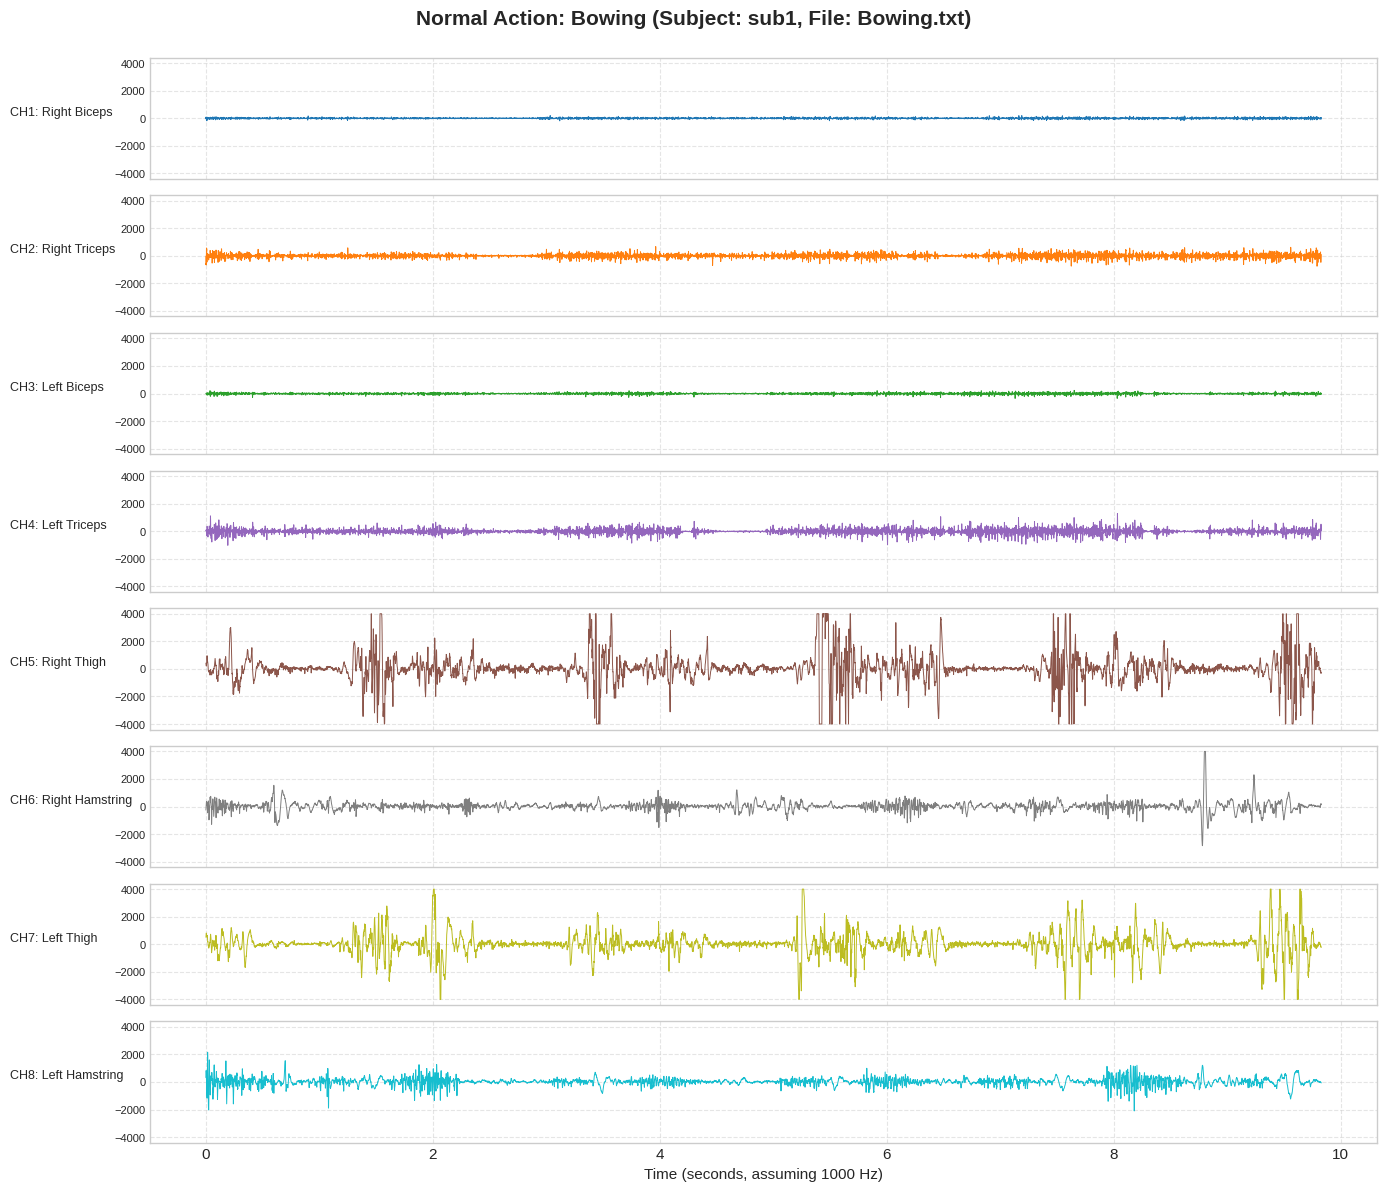

In [13]:
# Step 9: Plot Representative Normal Action Signal (e.g., Bowing - Subject 1)

sub1_dir = subject_dirs[0] if subject_dirs else DATASET_ROOT / "sub1"
normal_file = find_action_file(sub1_dir, "Bowing")

if normal_file is not None:
    normal_signal = read_emg_file(normal_file)
    plot_emg_channels(
        normal_signal,
        title=f"Normal Action: Bowing (Subject: {sub1_dir.name}, File: {normal_file.name})"
    )
else:
    print("Normal action file 'Bowing' not found for Subject 1.")

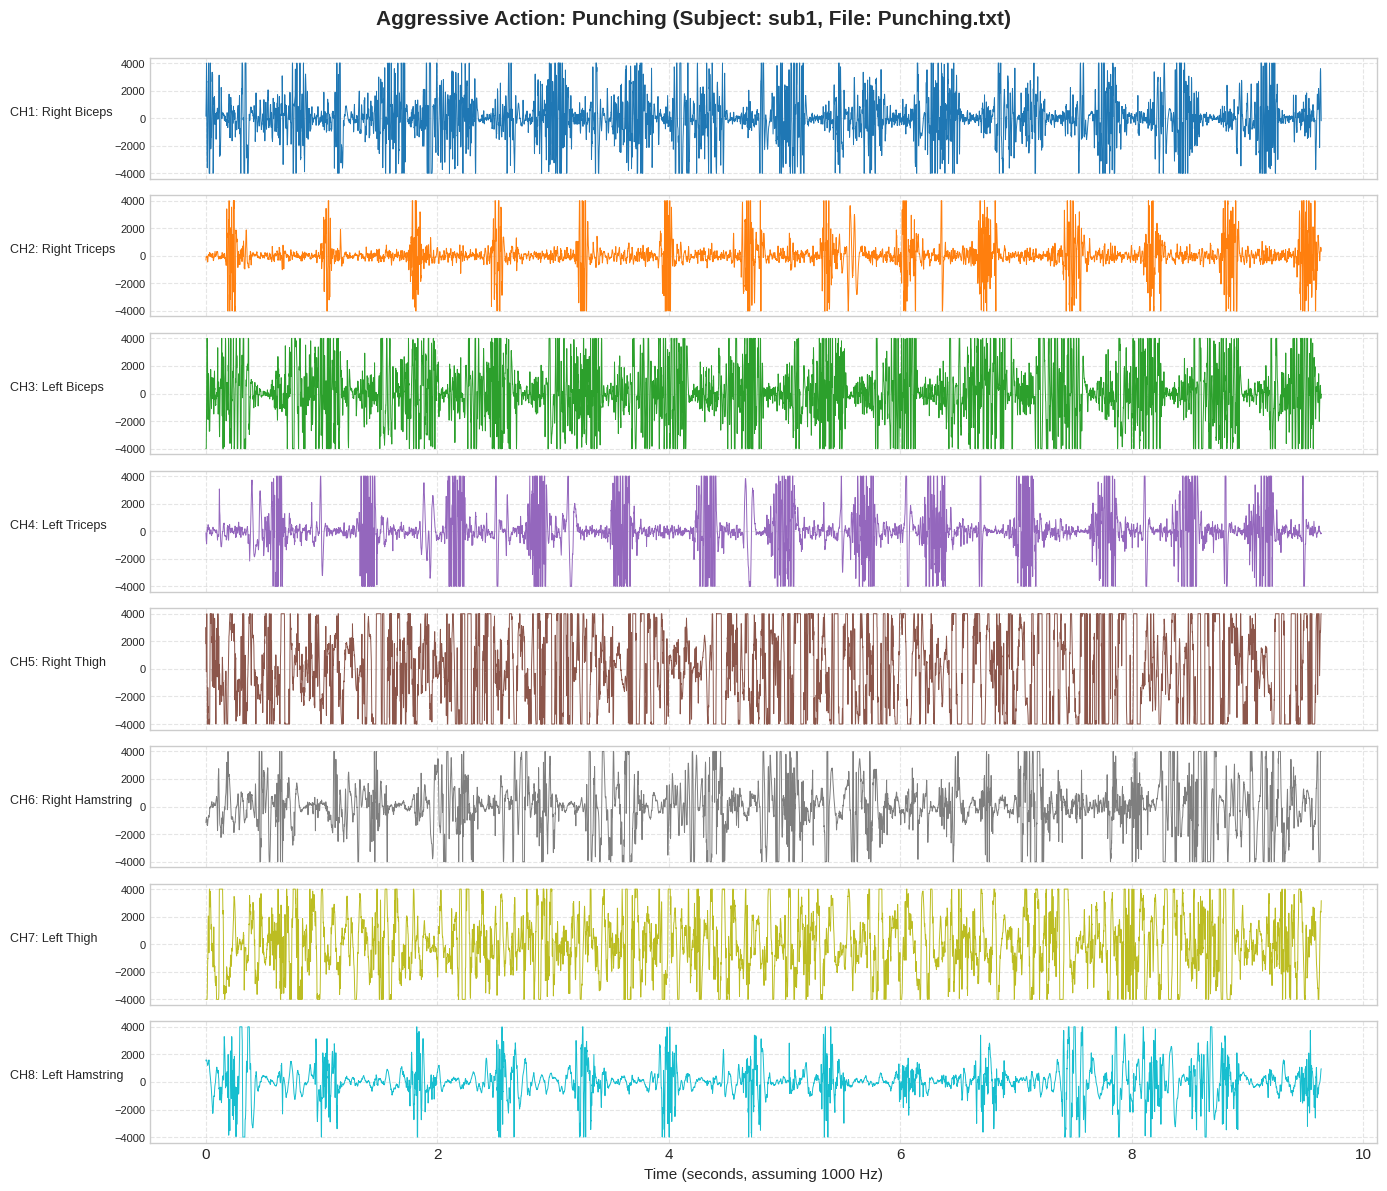

In [14]:
# Step 10: Plot Representative Aggressive Action Signal (e.g., Punching - Subject 1)

aggressive_file = find_action_file(sub1_dir, "Punching")

if aggressive_file is not None:
    aggressive_signal = read_emg_file(aggressive_file)
    plot_emg_channels(
        aggressive_signal,
        title=f"Aggressive Action: Punching (Subject: {sub1_dir.name}, File: {aggressive_file.name})"
    )
else:
    print("Aggressive action file 'Punching' not found for Subject 1.")

---
## 7. Summary of Exploration Findings

1. **Hierarchy & Files:** The dataset contains 4 subjects with both `.txt` and `.log` recordings, spanning 10 Normal and 10 Aggressive actions.
2. **Channel Integrity:** All verified files contain exactly 8 muscle channels tracking upper body (Biceps, Triceps) and lower body (Thighs, Hamstrings).
3. **Signal Signatures:**
   - **Bowing (Normal):** Shows sustained, moderate muscle recruitment in back/leg stabilisers (Thighs/Hamstrings) with minimal explosive arm bursts.
   - **Punching (Aggressive):** Shows sharp, rapid bursts in upper limbs (Right Biceps CH1, Right Triceps CH2) synchronized with rapid leg stabilization.
4. **Next Step:** In `02_feature_extraction.ipynb`, we partition verified trials and extract mean and population variance features across segmented windows.